# 01. Dataset Overview, Summary Statistics & Cardinality Review
## Hotel Cancellation Prediction Project

### Objectives & Context
1. **Target Formulation (`is_canceled`):**
   - The target is a binary indicator ($0$ = Not Canceled / Checked Out, $1$ = Canceled or No-Show).
   - This defines the task as a binary classification problem. A calibrated Logistic Regression model serves as an interpretable baseline alongside tree-based ensembles (LightGBM/XGBoost).
2. **Whole Dataset Summary Statistics:**
   - Numerical distribution attributes (mean, standard deviation, quartiles, extreme ranges).
   - Categorical summary (cardinality, modal class, class frequencies).
3. **Missing Value Diagnostics:**
   - Identification of missing values across all 32 features, distinguishing genuine missing data from structural domain indicators (e.g., bookings made without an agent or corporate sponsor).
4. **Cardinality & Data Type Reclassification Review:**
   - Systematic inspection of unique value counts and unique-to-row ratios.
   - Determining which numeric columns represent discrete identifiers or categorical flags rather than continuous quantities.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Styling configurations
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

from hotel_cancellation_prediction.data.loader import load_raw_data

## 1. Data Ingestion & Initial Inspection

In [2]:
df = load_raw_data()
print(f"Total Rows: {df.shape[0]:,}")
print(f"Total Columns: {df.shape[1]}")
df.head()

2026-10-27 07:24:30 | INFO    | hotel_cancellation_prediction.data.loader:21 - Loading raw dataset from data\raw\hotel_bookings.csv


2026-10-27 07:24:30 | INFO    | hotel_cancellation_prediction.data.loader:24 - Loaded 119390 rows and 32 columns


Total Rows: 119,390
Total Columns: 32


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 2. Target Variable Analysis (`is_canceled`)

Since `is_canceled` is binary, we evaluate the baseline prior probability of cancellation. This baseline dictates the minimum naive benchmark accuracy and informs whether class-weighting / cost-sensitive calibration is required for logistic regression.

Target Class Breakdown:
                 Count  Percentage (%)
Checked-Out (0)  75166           62.96
Canceled (1)     44224           37.04


C:\Users\joshu\AppData\Local\Temp\ipykernel_10604\2748656107.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="is_canceled", palette=["#2ecc71", "#e74c3c"], ax=axes[0])
C:\Users\joshu\AppData\Local\Temp\ipykernel_10604\2748656107.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(["Checked-Out (0)", "Canceled (1)"])


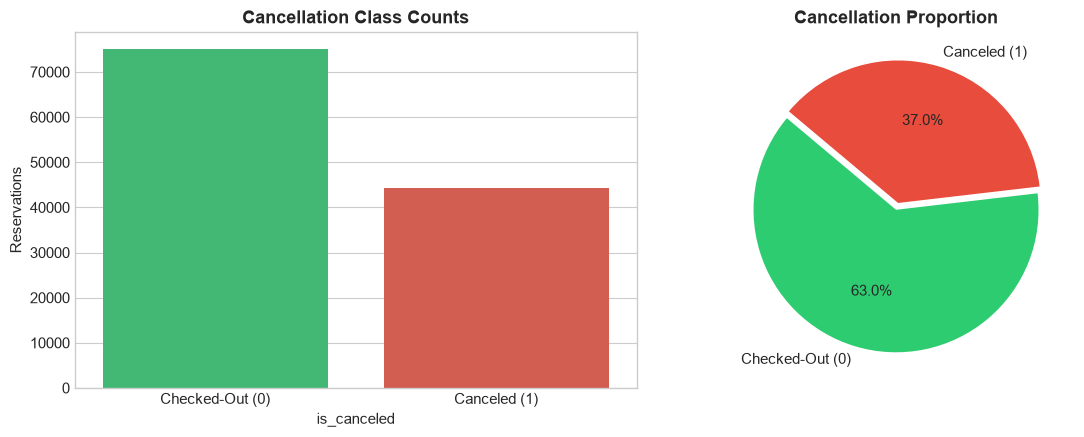

In [3]:
target_counts = df["is_canceled"].value_counts()
target_pcts = df["is_canceled"].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage (%)": target_pcts.round(2)
})
target_summary.index = ["Checked-Out (0)", "Canceled (1)"]
print("Target Class Breakdown:")
print(target_summary)

# Plot class balance
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.countplot(data=df, x="is_canceled", palette=["#2ecc71", "#e74c3c"], ax=axes[0])
axes[0].set_title("Cancellation Class Counts", fontweight="bold")
axes[0].set_xticklabels(["Checked-Out (0)", "Canceled (1)"])
axes[0].set_ylabel("Reservations")

axes[1].pie(
    target_pcts,
    labels=["Checked-Out (0)", "Canceled (1)"],
    autopct="%1.1f%%",
    colors=["#2ecc71", "#e74c3c"],
    startangle=140,
    explode=(0, 0.05)
)
axes[1].set_title("Cancellation Proportion", fontweight="bold")
plt.tight_layout()
plt.show()

## 3. Dataset Summary Statistics

We partition summary statistics into numerical variables (evaluating dispersion, bounds, and skewness) and categorical variables (evaluating modal frequencies and diversity).

In [4]:
# Numerical variables summary
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
num_summary = df[num_cols].describe().T
num_summary["IQR"] = num_summary["75%"] - num_summary["25%"]
num_summary["skew"] = df[num_cols].skew()
print("Numerical Features Summary:")
display(num_summary.round(2))

Numerical Features Summary:


,count,mean,std,min,25%,50%,75%,max,IQR,skew
is_canceled,119390.0,0.37,0.48,0.00,0.00,0.00,1.0,1.0,1.00,0.54
lead_time,119390.0,104.01,106.86,0.00,18.00,69.00,160.0,737.0,142.00,1.35
arrival_date_year,119390.0,2016.16,0.71,2015.00,2016.00,2016.00,2017.0,2017.0,1.00,-0.23
arrival_date_week_number,119390.0,27.17,13.61,1.00,16.00,28.00,38.0,53.0,22.00,-0.01
arrival_date_day_of_month,119390.0,15.80,8.78,1.00,8.00,16.00,23.0,31.0,15.00,-0.00
stays_in_weekend_nights,119390.0,0.93,1.00,0.00,0.00,1.00,2.0,19.0,2.00,1.38
stays_in_week_nights,119390.0,2.50,1.91,0.00,1.00,2.00,3.0,50.0,2.00,2.86
adults,119390.0,1.86,0.58,0.00,2.00,2.00,2.0,55.0,0.00,18.32
children,119386.0,0.10,0.40,0.00,0.00,0.00,0.0,10.0,0.00,4.11
babies,119390.0,0.01,0.10,0.00,0.00,0.00,0.0,10.0,0.00,24.65


In [5]:
# Categorical variables summary
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()
cat_summary = df[cat_cols].describe().T
print("Categorical Features Summary:")
display(cat_summary)

Categorical Features Summary:


,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


## 4. Missing Value Diagnostics

We examine missing rates across all columns. In tabular booking datasets, missing values often encode specific operational states rather than missing-at-random noise (e.g. `NULL` in `agent` indicates a direct booking).

Columns with Missing Data:


,Missing Count,Percentage (%),Data Type
company,112593,94.307,float64
agent,16340,13.686,float64
country,488,0.409,str
children,4,0.003,float64


C:\Users\joshu\AppData\Local\Temp\ipykernel_10604\1626170153.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_df["Percentage (%)"], y=missing_df.index, palette="mako")


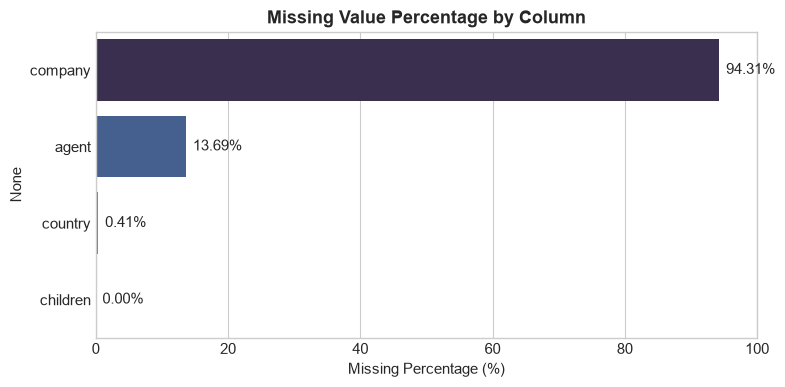

In [6]:
missing_counts = df.isnull().sum()
missing_pcts = (missing_counts / len(df)) * 100

missing_df = pd.DataFrame({
    "Missing Count": missing_counts,
    "Percentage (%)": missing_pcts.round(3),
    "Data Type": df.dtypes
}).loc[lambda x: x["Missing Count"] > 0].sort_values(by="Missing Count", ascending=False)

print("Columns with Missing Data:")
display(missing_df)

if not missing_df.empty:
    plt.figure(figsize=(8, 4))
    sns.barplot(x=missing_df["Percentage (%)"], y=missing_df.index, palette="mako")
    plt.title("Missing Value Percentage by Column", fontweight="bold")
    plt.xlabel("Missing Percentage (%)")
    plt.xlim(0, 100)
    for index, value in enumerate(missing_df["Percentage (%)"]):
        plt.text(value + 1, index, f"{value:.2f}%", va="center")
    plt.tight_layout()
    plt.show()

### Missing Value Insights & Handling Strategies:
- **`company` (94.30% missing):** Represents corporate client ID. The overwhelming majority of bookings are leisure or non-corporate transient. Rather than imputing the numeric ID, we should engineer a binary flag `is_company_booking = company.notnull().astype(int)`.
- **`agent` (13.69% missing):** Represents travel agency ID. Missing values signify direct consumer reservations without agency intermediation. Impute missing with an explicit category indicator (e.g. `0` or `"Direct/None"`).
- **`country` (0.41% missing / 488 rows):** Can be imputed with the mode (`"PRT"` - Portugal) or assigned to an `"Unknown"` category.
- **`children` (4 rows missing):** Negligible count; can be imputed with `0.0` or median.

## 5. Column Cardinality & Reclassification Review

We compute the number of unique values, uniqueness ratio, and analyze whether numeric types represent continuous scale variables or discrete/categorical IDs.

In [7]:
cardinality_records = []

for col in df.columns:
    n_unique = df[col].nunique(dropna=True)
    pct_unique = (n_unique / len(df)) * 100
    dtype = df[col].dtype
    sample_vals = df[col].dropna().unique()[:4].tolist()

    # Assess reclassification
    recommendation = "Keep as Numerical"
    if col in ["agent", "company"]:
        recommendation = "Reclassify: Categorical ID (High Cardinality)"
    elif col in ["is_repeated_guest", "is_canceled"]:
        recommendation = "Binary Indicator (Categorical Flag)"
    elif col in ["arrival_date_year", "arrival_date_week_number", "arrival_date_day_of_month"]:
        recommendation = "Reclassify: Temporal/Discrete Categorical Factor"
    elif dtype == "object" or dtype == "string":
        recommendation = "Keep as Categorical"
    elif n_unique < 15 and dtype in ["int64", "float64"]:
        recommendation = "Low Cardinality Discrete / Ordinal"

    cardinality_records.append({
        "Column": col,
        "Current Dtype": str(dtype),
        "Unique Values": n_unique,
        "Unique Ratio (%)": round(pct_unique, 4),
        "Sample Values": sample_vals,
        "Proposed Feature Type": recommendation
    })

cardinality_df = pd.DataFrame(cardinality_records)
cardinality_df.sort_values(by="Unique Values", ascending=False, inplace=True)
display(cardinality_df)

C:\Users\joshu\AppData\Local\Temp\ipykernel_10604\3507530454.py:32: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  cardinality_df.sort_values(by="Unique Values", ascending=False, inplace=True)


,Column,Current Dtype,Unique Values,Unique Ratio (%),Sample Values,Proposed Feature Type
27,adr,float64,8879,7.4370,"[0.0, 75.0, 98.0, 107.0]",Keep as Numerical
31,reservation_status_date,str,926,0.7756,"[2015-07-01, 2015-07-02, 2015-07-03, 2015-05-06]",Keep as Categorical
2,lead_time,int64,479,0.4012,"[342, 737, 7, 13]",Keep as Numerical
24,company,float64,352,0.2948,"[110.0, 113.0, 270.0, 178.0]",Reclassify: Categorical ID (High Cardinality)
23,agent,float64,333,0.2789,"[304.0, 240.0, 303.0, 15.0]",Reclassify: Categorical ID (High Cardinality)
13,country,str,177,0.1483,"[PRT, GBR, USA, ESP]",Keep as Categorical
25,days_in_waiting_list,int64,128,0.1072,"[0, 50, 47, 65]",Keep as Numerical
18,previous_bookings_not_canceled,int64,73,0.0611,"[0, 1, 2, 3]",Keep as Numerical
5,arrival_date_week_number,int64,53,0.0444,"[27, 28, 29, 30]",Reclassify: Temporal/Discrete Categorical Factor
8,stays_in_week_nights,int64,35,0.0293,"[0, 1, 2, 3]",Keep as Numerical


In [8]:
# Summary table of proposed reclassifications
reclass_summary = cardinality_df[cardinality_df["Proposed Feature Type"].str.startswith("Reclassify")][
    ["Column", "Current Dtype", "Unique Values", "Proposed Feature Type"]
]
print("Columns Recommended for Reclassification:")
display(reclass_summary)

Columns Recommended for Reclassification:


,Column,Current Dtype,Unique Values,Proposed Feature Type
24,company,float64,352,Reclassify: Categorical ID (High Cardinality)
23,agent,float64,333,Reclassify: Categorical ID (High Cardinality)
5,arrival_date_week_number,int64,53,Reclassify: Temporal/Discrete Categorical Factor
6,arrival_date_day_of_month,int64,31,Reclassify: Temporal/Discrete Categorical Factor
3,arrival_date_year,int64,3,Reclassify: Temporal/Discrete Categorical Factor


## 6. Key Takeaways & Pipeline Action Items

1. **Target Imbalance:**
   - ~37.0% of all bookings are canceled.
   - For logistic regression, the dataset is sufficiently balanced to fit without severe synthetic resampling, but class weights or probability threshold calibration will ensure precise probabilities for the glide path overbooking calculations.
2. **Structural Missingness:**
   - `company` and `agent` should be converted from raw floats to categorical flags (`has_company`, `has_agent`) and high-frequency category buckets.
3. **Reclassifications for Preprocessing Pipeline:**
   - **`agent` & `company`:** Treat as high-cardinality nominal IDs, not continuous numbers.
   - **`is_repeated_guest`:** Treat as a binary factor.
   - **Temporal Features (`arrival_date_year`, `arrival_date_week_number`):** Treat as seasonal factors or cyclical sine/cosine encodings, rather than linear numeric inputs.